# Unsupervised Learning: PCA & Clustering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/konstantin-schekotihin/dl_course/blob/master/AI-ML/07_unsupervised.ipynb)

In [1]:
import matplotlib.image as mpimg
# Setup & configuration (skip in presentation slides)
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
from ipywidgets import fixed, interact
from sklearn.datasets import load_iris
import sklearn.cluster as cl

# Course helpers: installed from PyPI in Colab, from the repository's .venv locally
import sys
if "google.colab" in sys.modules:
    %pip install -q dl-course
from dl_course import aiml as hp
hp.setup_theme()

## 1. Foundations of Unsupervised Learning

<center>
    <img src="https://raw.githubusercontent.com/konstantin-schekotihin/dl_course/master/shared/images/unsupervised.jpg" width="80%"/>
</center>

### Goals and Challenges of Unsupervised Learning

+ What should we do, if there are no labels?
    - There is no simple goal for analysis, the methods are more subjective
    - However, these methods are very important in various applications 
+ Can we represent the data in some informative way and study its properties?

+ Examples:
    - Documents can be grouped by words occurring in them
    - Patients by results of various tests
    - Products by technical features
+ Unlabeled data is often more easy to get! 
    - No mighty oracle providing the labels is required

### Supervised vs. Unsupervised Paradigms
+ Dimensionality reduction:
    - Given a set of features and their observations, can we derive new features that are better suitable for analysis?
    - *Principal Components Analysis* (PCA): a tool used for data visualization or data preprocessing before supervised techniques are applied

## 2. Principal Components Analysis (PCA)
+ Assume you face a dataset with a large set of correlated features
+ PCA allows us to summarize this set with a smaller number of "synthetic" features that collectively explain most of the variance in the original dataset
+ Given a dataset with $N$ observations of $D$ features

### Motivating Case Study: US Arrests

+ Consider a data set containing statistics for each of the 50 US states in 1973:
    - arrests per 100,000 residents for assault, murder, and rape;
    - percent of the population living in urban areas

In [2]:
# Load USArrests dataset
us = pd.read_csv(hp.get_data_path("USArrests.csv"))
states = us.pop(us.columns[0])
us.head()


,Murder,Assault,UrbanPop,Rape
0,13.2,236,58,21.2
1,10.0,263,48,44.5
2,8.1,294,80,31.0
3,8.8,190,50,19.5
4,9.0,276,91,40.6


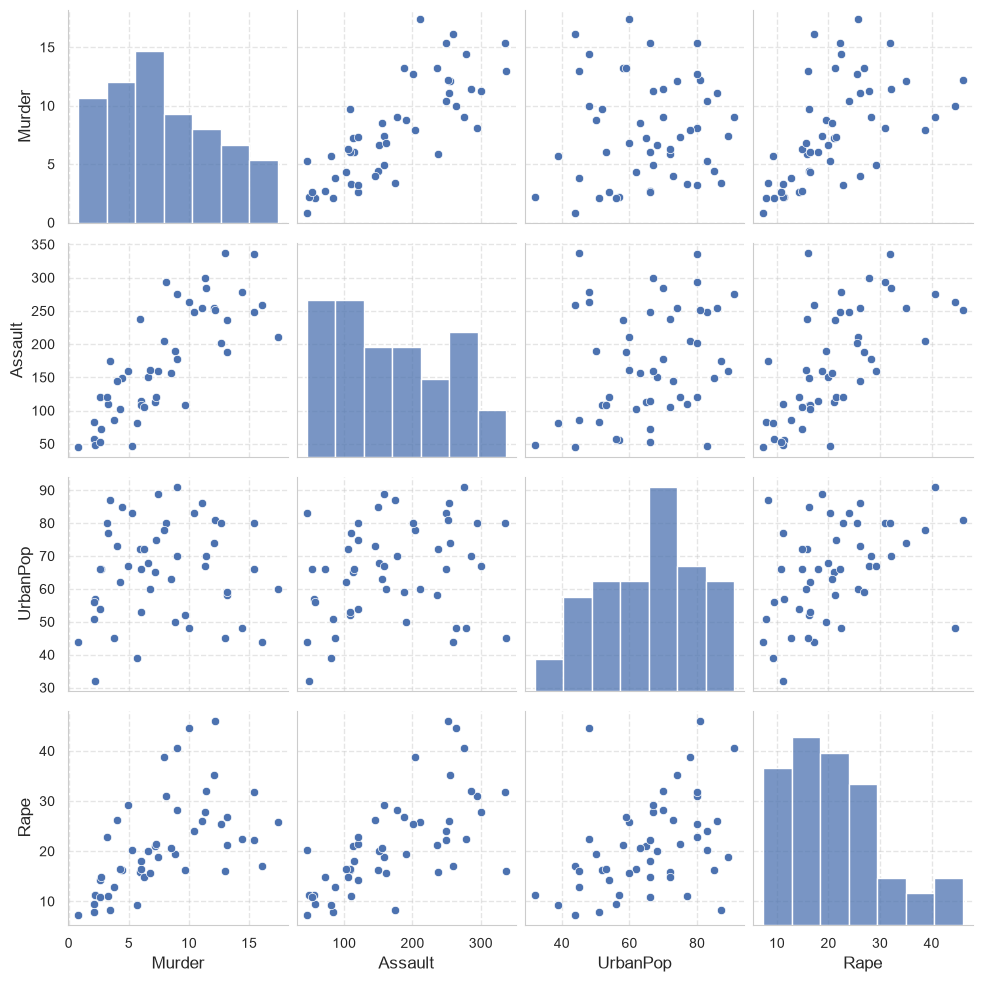

In [3]:
sns.pairplot(us);

In [4]:
us.describe()

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


### Feature Standardization

- Because variance depends on feature measurement units, we standardize each feature column to have zero mean and unit variance:

$$
x_{ni}' = \frac{x_{ni} - \bar{x}_i}{s_i}
$$

- where sample mean $\bar{x}_i$ and standard deviation $s_i$ are defined as:

$$
\bar{x}_i = \frac{1}{N} \sum_{n=1}^{N} x_{ni}, \quad s_i = \sqrt{\frac{1}{N-1} \sum_{n=1}^{N} (x_{ni} - \bar{x}_i)^2}
$$

> 💡 **Key Takeaway:** Unstandardized features with large numerical magnitudes arbitrarily dominate distance metrics and principal component variances.


In [5]:
def standardize(T):
    """Standardize feature tensor columns to zero mean and unit variance."""
    means = T.mean(dim=0, keepdim=True)
    stds = T.std(dim=0, keepdim=True)
    return (T - means) / stds

# Application of the standard scaler to the first two columns (for simplicity)
T_us = torch.tensor(us.values, dtype=torch.float32)
X_us = standardize(T_us)[:, [0, 1]]
df_us = pd.DataFrame(data=X_us.numpy(), columns=us.columns[[0, 1]])
df_us.describe()


,Murder,Assault
count,5.000000e+01,5.000000e+01
mean,-1.412630e-07,7.584691e-08
std,1.000000e+00,1.000000e+00
min,-1.604405e+00,-1.509042e+00
25%,-8.524836e-01,-7.410814e-01
50%,-1.235218e-01,-1.411126e-01
75%,7.948552e-01,9.388313e-01
max,2.206860e+00,1.994776e+00


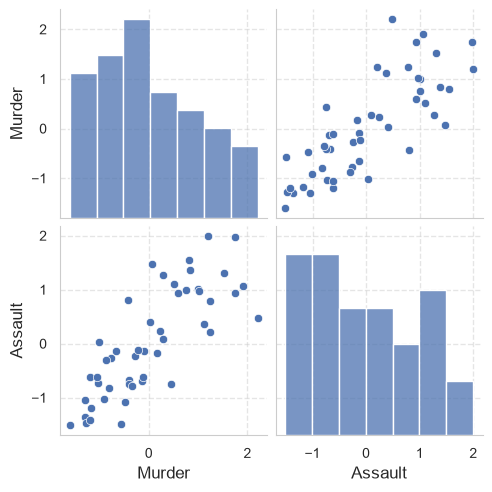

In [6]:
sns.pairplot(df_us);

In [7]:
def plot_scores(x=0, y=0):
    hp.plot_pca_scores(X_us, [x, y], x_label=us.columns[0], y_label=us.columns[1])

interact(plot_scores, x=fixed(1), y=(-1,1,0.2));

interactive(children=(FloatSlider(value=0.0, description='y', max=1.0, min=-1.0, step=0.2), Output()), _dom_cl…

### Principal Components & Direction Vectors

- For data matrix $\mathbf{X} \in \mathbb{R}^{N \times D}$ with centered observation vectors $\mathbf{x}_n \in \mathbb{R}^D$:
- The first **principal component** projection is a linear combination defined by unit direction vector $\mathbf{u}_1 \in \mathbb{R}^D$:

$$
z_{n1} = \mathbf{u}_1^\mathrm{T} \mathbf{x}_n = \sum_{i=1}^{D} u_{i1} x_{ni}, \quad \text{such that } \|\mathbf{u}_1\|^2 = \mathbf{u}_1^\mathrm{T} \mathbf{u}_1 = 1
$$

- Vector $\mathbf{u}_1 = (u_{11}, \dots, u_{D1})^\mathrm{T}$ represents the **first principal direction** (loadings).
- The projected values $z_{11}, \dots, z_{N1}$ are called **principal component scores**.


### Maximizing Explained Variance

- We seek unit vector $\mathbf{u}_1$ that maximizes the sample variance of the projected data:

$$
\max_{\mathbf{u}_1} \frac{1}{N-1} \sum_{n=1}^{N} (\mathbf{u}_1^\mathrm{T} \mathbf{x}_n)^2 = \max_{\mathbf{u}_1} \mathbf{u}_1^\mathrm{T} \mathbf{S} \mathbf{u}_1 \quad \text{subject to } \mathbf{u}_1^\mathrm{T} \mathbf{u}_1 = 1
$$

- where $\mathbf{S} = \frac{1}{N-1} \mathbf{X}^\mathrm{T} \mathbf{X}$ is the sample covariance matrix of the centered data.
- Using Lagrange multipliers: $\mathbf{S} \mathbf{u}_1 = \lambda_1 \mathbf{u}_1$.
- The optimal direction $\mathbf{u}_1$ is the **eigenvector** of $\mathbf{S}$ with largest eigenvalue $\lambda_1$!


### Spectral & Singular Value Decomposition (SVD)

- **Eigendecomposition of Covariance Matrix** $\mathbf{S} = \frac{1}{N-1} \mathbf{X}^\mathrm{T}\mathbf{X}$:

$$
\mathbf{S} = \mathbf{U} \boldsymbol{\Lambda} \mathbf{U}^\mathrm{T}
$$

  - Columns $\mathbf{u}_1, \dots, \mathbf{u}_D$ of the orthogonal matrix $\mathbf{U}$ are the principal directions (eigenvectors).
  - Diagonal entries $\lambda_j$ in $\boldsymbol{\Lambda}$ represent variance explained by component $j$.

- **Equivalence via SVD**: For the centered matrix $\mathbf{X} = \mathbf{L} \, \mathrm{diag}(\sigma_1, \dots, \sigma_D) \, \mathbf{U}^\mathrm{T}$ (left singular vectors in $\mathbf{L}$, singular values $\sigma_j$, principal directions in $\mathbf{U}$):
  - Principal component scores are computed directly as $\mathbf{Z} = \mathbf{X} \mathbf{U} = \mathbf{L} \, \mathrm{diag}(\sigma_1, \dots, \sigma_D)$.
  - Eigenvalues satisfy $\lambda_j = \frac{\sigma_j^2}{N-1}$.


### Empirical PCA: Small 2D Example

+ Apply PCA to find the first two columns of the *standardized* US Arrests dataset 

In [8]:
def std_PCA(X, k=2):   
    n = X.size()[0]
    if (k>X.size()[1]): 
        raise ValueError('k must be smaller or equal to {}'.format(X.size()[1]))

    u,d,v = torch.svd(X)
    d = torch.diag(d)
    comps = v[:,:k].t()
    var_exp = torch.matmul(d,d)/(n-1)
    scores =  torch.matmul(u,d)[:,:k]
    loadings = torch.matmul(v, torch.sqrt(var_exp))
    return (scores, comps, torch.diag(var_exp)[:k], loadings[:k].t())

sc_s, cs_s, ve_s, l_s = std_PCA(X_us)
print("Direction of the first component: ({:.3f}, {:.3f})".format(cs_s[0,0], cs_s[0,1]))
print("Direction of the second component:  ({:.3f}, {:.3f})".format(cs_s[1,0], cs_s[1,1]))

Direction of the first component: (-0.707, -0.707)
Direction of the second component:  (0.707, -0.707)


+ The first principal direction $\mathbf{u}_1 = (-0.707, -0.707)^\mathrm{T}$ defines a direction in the feature space along which the data varies most:

$$
z_{n1} = -0.707 \, x_{n1} - 0.707 \, x_{n2}
$$

+ The second principal direction $\mathbf{u}_2 = (0.707, -0.707)^\mathrm{T}$ is orthogonal to the first:

$$
z_{n2} = 0.707 \, x_{n1} - 0.707 \, x_{n2}
$$

  where $x_{n1}$ and $x_{n2}$ are the standardized *Murder* and *Assault* rates of state $n$.

- Since we have $50$ observations, the score vectors $\mathbf{z}_1$ and $\mathbf{z}_2$ have also $50$ values
- The original data points and a principle direction are shown on the left
- Projections of the data points on the axis - on the right

In [9]:
def plot_dirs(i=0):
    plot_scores(cs_s[i, 0], cs_s[i, 1])

interact(plot_dirs, i=(0, 1));


interactive(children=(IntSlider(value=0, description='i', max=1), Output()), _dom_classes=('widget-interact',)…

### Loading Vectors & Feature Contributions

+ A *loading vector* is a principal direction scaled by the square root of the variance of the original variable it explains 
    + The red arrow shows the direction of the first component and the orange one -- of the second
    + Length of the vectors - proportion of the variance explained

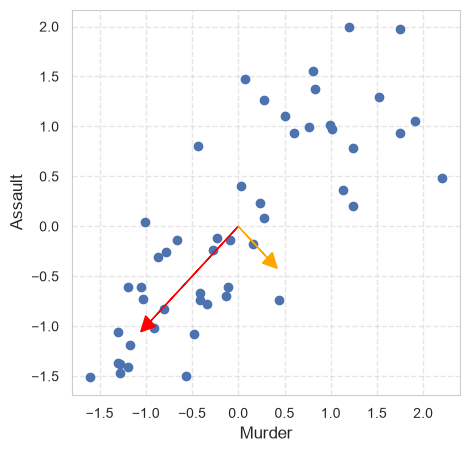

In [10]:
colors=['red', 'orange']
fig = plt.figure(figsize=(5,5))
plt.scatter(X_us[:,0],X_us[:,1])
plt.xlabel(us.columns[0])
plt.ylabel(us.columns[1])

for i in range(2):
    plt.arrow(0, 0, l_s[i,0], l_s[i,1], ec=colors[i],
              head_width=0.15, head_length=0.15, fc=colors[i])

### Full US Arrests Analysis

- All four components of the data set 

In [11]:
X_full = standardize(T_us)
sc_f, cs_f, ve_f, l_f = std_PCA(X_full, k=4)
print("Principal directions are given in the rows")
pd.DataFrame(data=cs_f.numpy(), columns=us.columns)

Principal directions are given in the rows


,Murder,Assault,UrbanPop,Rape
0,-0.535899,-0.583184,-0.278191,-0.543432
1,0.418181,0.187986,-0.872806,-0.167319
2,-0.341233,-0.268149,-0.378016,0.817778
3,0.649228,-0.743407,0.133878,0.089024


- Visualizing the impact of variables on each component can be done using heat maps

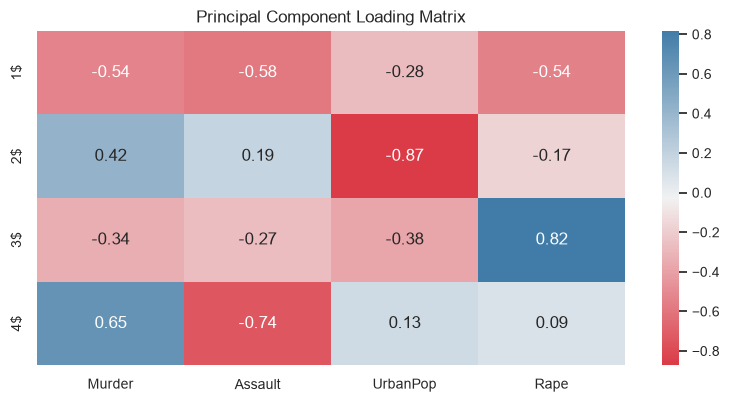

In [12]:
hp.plot_loading_heatmap(
    cs_f,
    x_labels=list(us.columns),
    y_labels=[f"{i+1}$" for i in range(len(cs_f))],
    title="Principal Component Loading Matrix",
)

- Variance explained by each component

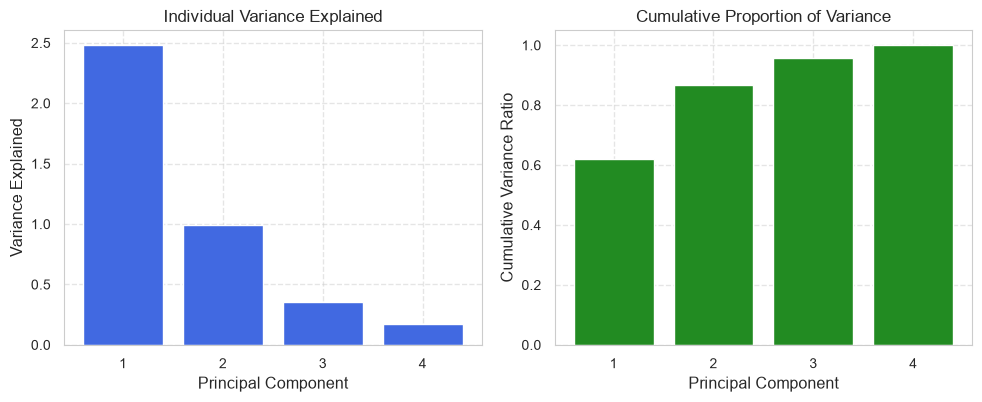

In [13]:
hp.plot_variance_explained(ve_f)

### PCA Biplot Interpretation

+ Biplot shows both principal component scores and loadings

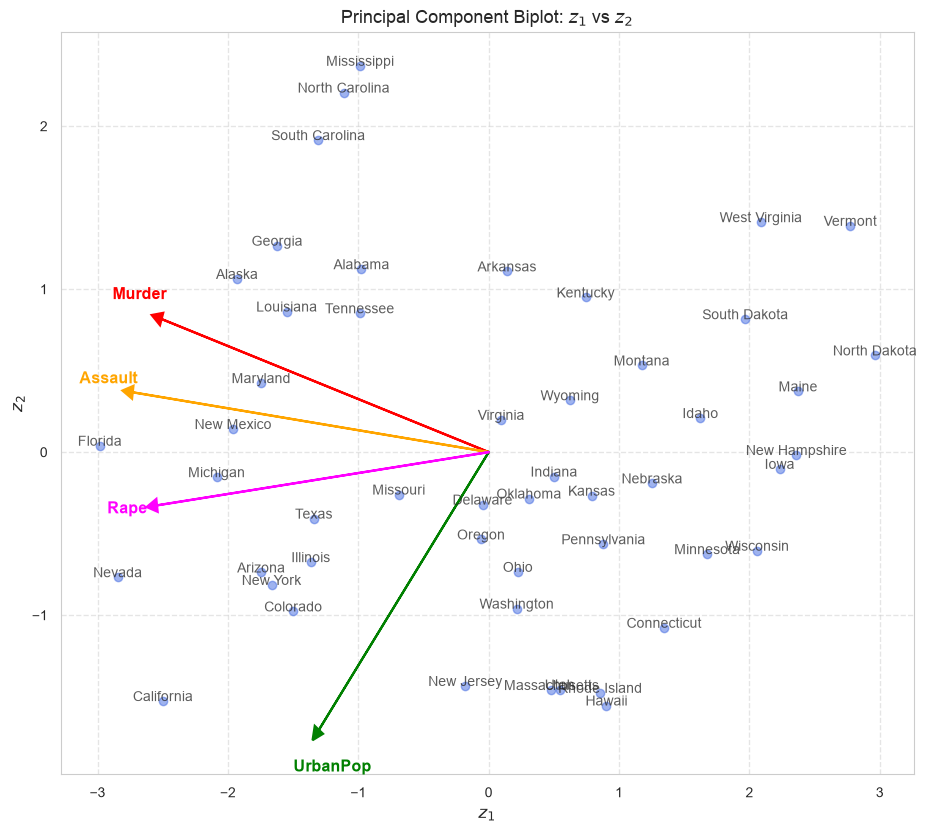

In [14]:
z1, z2 = 0, 1
hp.plot_pca_biplot(z1, z2, sc_f, l_f, states, us.columns, colors=['red', 'orange', 'green', 'magenta'])

+ State names - scores for the first two principal components
+ Arrows - show loading vectors of the first two principal components (axes top and right)
+ First loading vector places appr. equal weight on *Assault*, *Murder* and *Rape* - roughly - measure of overall rates of serious crimes
    - Three "crime" variables are correlated - states with a high rate in one crime tend to have higher rates in other crimes
+ Second vector places most weight on *UrbanPop* and much less on other features
+ Score vectors:
    - California high urbanization and crime rate
    - Vermont low urbanization and low crime rate
    - Florida high crime rate and average urbanization

### Multidimensional Exploration: The Iris Benchmark

- Consider a data set containing measurement of 150 iris flowers:
    - 3 types of flowers: setosa, versicolor, and virginica
    - 4 features: width and length of sepal and petal leaves


<center>
    <img src="https://raw.githubusercontent.com/konstantin-schekotihin/dl_course/master/shared/images/slide8.png" width="50%"/>
</center>

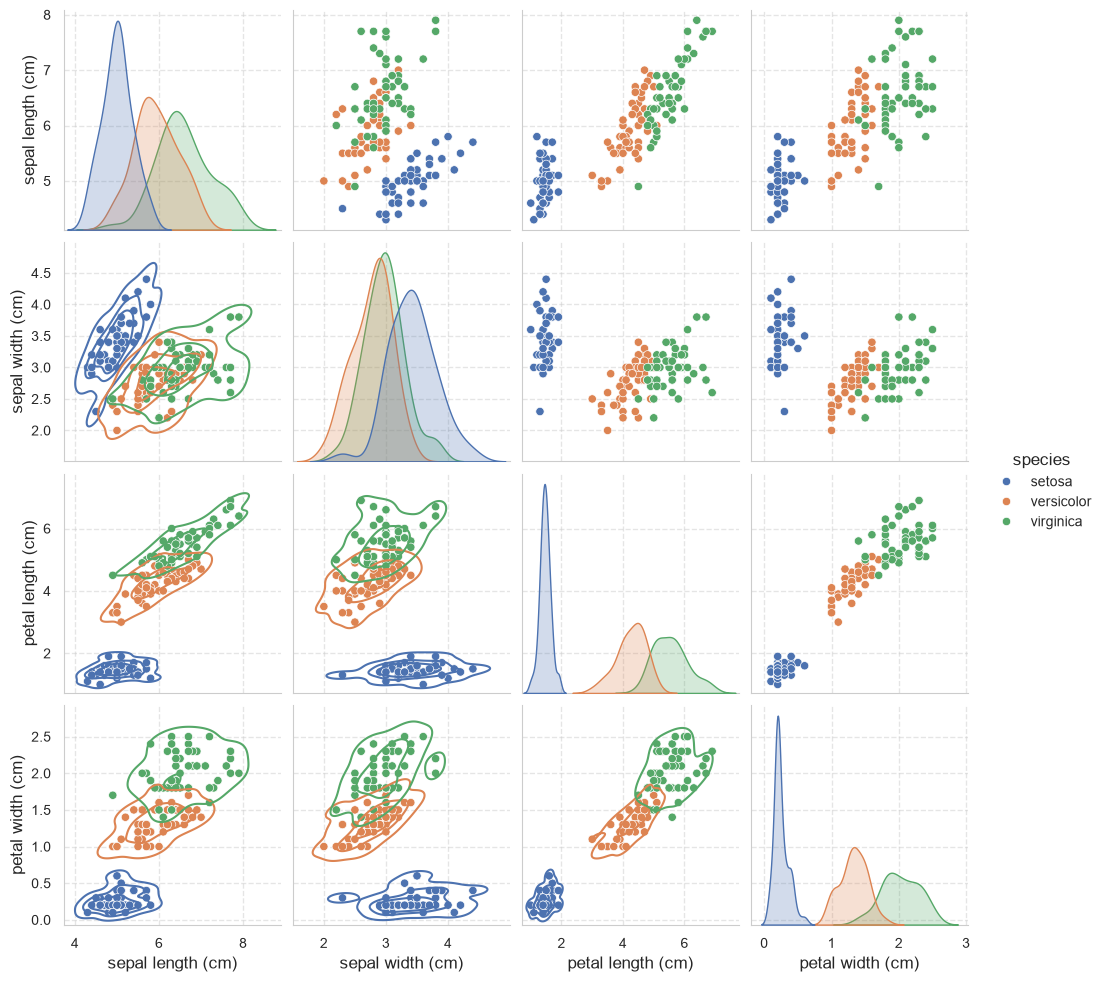

In [15]:
# Load Iris dataset
iris_obj = load_iris(as_frame=True)
dfi = iris_obj.frame.rename(columns={'target': 'species'})
dfi['species'] = dfi['species'].map(dict(enumerate(iris_obj.target_names)))
fig = sns.pairplot(dfi, hue="species")
fig.map_lower(sns.kdeplot, levels=4, color=".2");

In [16]:
X_iris = standardize(torch.tensor(dfi.iloc[:,0:4].values, dtype=torch.float32))
sc_i, cs_i, ve_i, l_i = std_PCA(X_iris, k=4)
print("Principal directions are given in the rows")
pd.DataFrame(data=cs_i.numpy(), columns=dfi.columns[0:4])

Principal directions are given in the rows


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,0.521066,-0.269347,0.580413,0.564857
1,-0.377418,-0.923296,-0.024492,-0.066942
2,0.719566,-0.244382,-0.142126,-0.634273
3,0.261286,-0.123510,-0.801449,0.523597


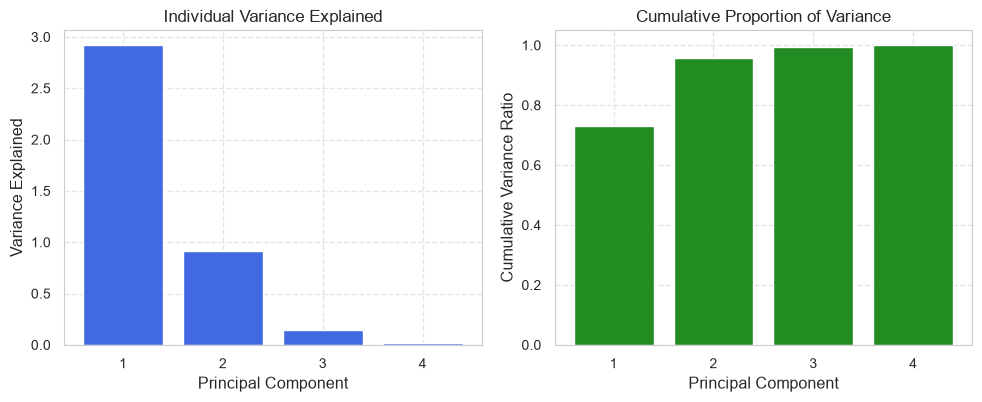

In [17]:
hp.plot_variance_explained(ve_i)

- Biplot for the two first principal components of iris data set

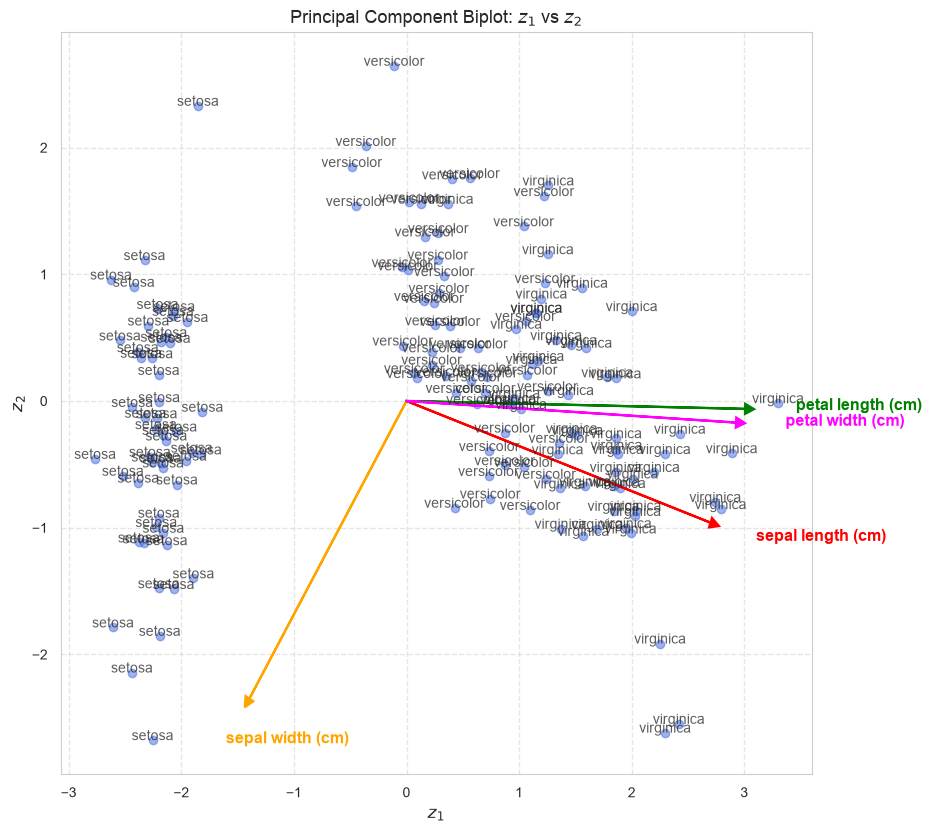

In [18]:
z1, z2 = 0, 1
hp.plot_pca_biplot(z1, z2, sc_i, l_i, dfi["species"], dfi.columns, 
       colors=['red', 'orange', 'green', 'magenta'])

### Low-Rank Approximation: Image Compression

+ Application of PCA to every of the three color channels of an image
+ The result shows an image obtained by using only 15 out of 320 principle components

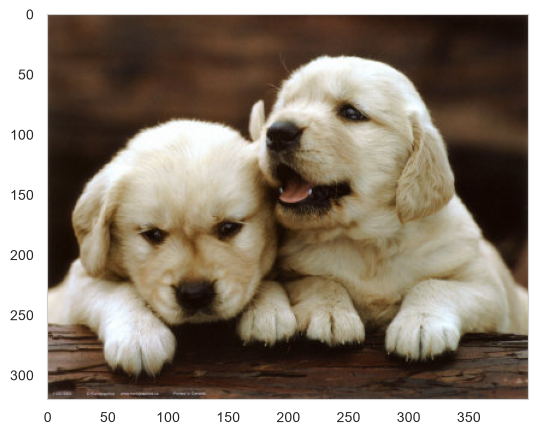

In [19]:
img = mpimg.imread(hp.get_file("puppy.jpeg"))
plt.imshow(img)
plt.grid(None);

In [20]:
interact(lambda comps=15: hp.compress_image_svd(img, comps=comps, std_pca_fn=std_PCA), comps=(5, 300, 5), continuous_update=False);

interactive(children=(IntSlider(value=15, description='comps', max=300, min=5, step=5), Output()), _dom_classe…

## 3. Clustering Algorithms

### Grouping Observations into Cohesive Subsets
- *Clustering* refers to an unsupervised family of methods for finding subgroups, or *clusters*, in a dataset.
- Every group is distinct and comprises observations that can be considered *similar*.

> ❓ **Core Problem:** What actually does "similar" mean? How can we quantify the similarity or distance between two or more observations?


### Distance & Similarity Measures in Clustering

- Clustering groups observations based on pairwise dissimilarity.
- Recall the **Minkowski distance family** *(from Lecture 01)*:
  - In continuous clustering, the most prevalent metric is the **squared Euclidean distance** ($L_2^2$):

$$
d^2(\mathbf{x}_n, \mathbf{x}_{n'}) = \|\mathbf{x}_n - \mathbf{x}_{n'}\|_2^2 = \sum_{i=1}^{D} (x_{ni} - x_{n'i})^2
$$

- **Domain-Specific Metric Choice**:
  - Continuous physical attributes: Euclidean ($L_2$) or Manhattan ($L_1$) distance *(from Lecture 01)*.
  - High-dimensional / text feature vectors: Cosine distance $1 - \frac{\mathbf{x}_n^\mathrm{T} \mathbf{x}_{n'}}{\|\mathbf{x}_n\|_2 \|\mathbf{x}_{n'}\|_2}$.
> ⚠️ **Important:** Because squared Euclidean distance scales with feature variances, feature standardization (`StandardScaler`) is a strict prerequisite before clustering.


### Within-Cluster Variation Measure

- Partition the indices of $N$ observations into $K$ disjoint clusters $\mathcal{S}_1, \dots, \mathcal{S}_K$ such that $\bigcup_{k=1}^K \mathcal{S}_k = \{1, \dots, N\}$ and $\mathcal{S}_k \cap \mathcal{S}_l = \emptyset$ for $k \neq l$.
- The total **within-cluster variation** objective measures aggregate cluster dispersion:

$$
J = \sum_{k=1}^{K} \frac{1}{2|\mathcal{S}_k|} \sum_{n \in \mathcal{S}_k} \sum_{n' \in \mathcal{S}_k} \|\mathbf{x}_n - \mathbf{x}_{n'}\|^2 = \sum_{k=1}^{K} \sum_{n \in \mathcal{S}_k} \|\mathbf{x}_n - \boldsymbol{\mu}_k\|^2
$$

- Here $\boldsymbol{\mu}_k = \frac{1}{|\mathcal{S}_k|} \sum_{n \in \mathcal{S}_k} \mathbf{x}_n$ is the **mean centroid** of cluster $\mathcal{S}_k$.
- Minimizing pairwise squared distances within each cluster is mathematically identical to minimizing squared deviations from cluster centroids!


### Overview of Clustering Approaches

- *$K$-means*: partition the observations into a predefined number $K$ of clusters
- *Hierarchical clustering*: create a dendrogram -- a tree-like visual representation of the observations -- representing all possible clusters, from 1 (root) to $N$ (leaves)
- *DBSCAN*: Density-Based Spatial Clustering of Applications with Noise, where the notion of density is defined as the number of points within a specified radius $\epsilon$

### The $K$-Means Objective Function

- $K$-Means optimizes the distortion measure $J$ over cluster assignments and centroids:

$$
\min_{\mathcal{S}_1, \dots, \mathcal{S}_K} J = \min_{\mathcal{S}_1, \dots, \mathcal{S}_K} \sum_{k=1}^{K} \sum_{n \in \mathcal{S}_k} \|\mathbf{x}_n - \boldsymbol{\mu}_k\|^2
$$

- Because evaluating all partitions is NP-hard, $K$-Means uses a fast iterative two-step coordinate descent (Lloyd's algorithm).


### Lloyd's Algorithm for $K$-Means

1. **Initialize**: Randomly choose $K$ observations as initial cluster centroids $\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_K$.
2. **Assignment Step**: Assign each observation $\mathbf{x}_n$ to its nearest centroid:

$$
c_n = \arg\min_{k \in \{1, \dots, K\}} \|\mathbf{x}_n - \boldsymbol{\mu}_k\|^2
$$

3. **Update Step**: Recompute each cluster centroid as the mean of its assigned members:

$$
\boldsymbol{\mu}_k = \frac{1}{|\mathcal{S}_k|} \sum_{n \in \mathcal{S}_k} \mathbf{x}_n
$$

4. **Iterate**: Repeat steps 2 and 3 until cluster assignments no longer change.


### Properties and Convergence of $K$-Means

+ The algorithm is guaranteed to decrease the value of objective at due to assignment step and relocation of centroids
+ Performs a local search strategy, similar to hill-climbing algorithm
+ Choice of initial centroids is essential for the performance
+ Important to run the algorithm multiple times with different initial configurations
+ Various algorithms try to select better centroids

### Improved Centroid Initialization: $K$-Means++

- Standard random initialization often converges to poor local minima.
- **$K$-Means++ Algorithm**:
  1. Select the first centroid $\boldsymbol{\mu}_1$ uniformly at random from observations $\{\mathbf{x}_n\}$.
  2. For each sample $\mathbf{x}_n$, compute shortest distance $d(\mathbf{x}_n)$ to existing centroids.
  3. Choose the next centroid with probability proportional to squared distance:

$$
p(\mathbf{x}_n) = \frac{d(\mathbf{x}_n)^2}{\sum_{m=1}^{N} d(\mathbf{x}_m)^2}
$$

  4. Repeat until all $K$ centroids are initialized.

- **Theoretical Guarantee**: Achieves $\mathcal{O}(\log K)$ competitive ratio to optimal clustering.


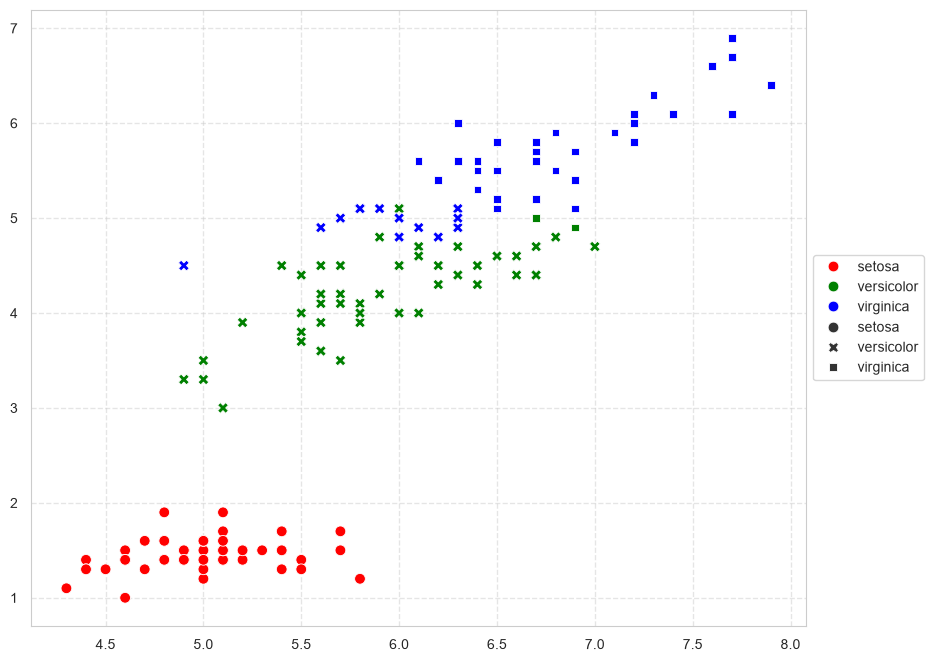

In [21]:
import sklearn.cluster as cl

# Load Iris dataset
iris_obj = load_iris(as_frame=True)
df = iris_obj.frame.rename(columns={'target': 'species'})
df['species'] = df['species'].map(dict(enumerate(iris_obj.target_names)))
X = df.to_numpy()[:,0:4]
classes={0 : 'setosa', 1 : 'versicolor', 2 : 'virginica'}

km = cl.KMeans(n_clusters=3, init='k-means++').fit(X)
km_labels = [classes[i] for i in km.labels_] 

plt.figure(figsize=(10, 8))
g = sns.scatterplot(x=X[:,0], y=X[:,2], hue=df['species'], s=60, style=km_labels,
                palette=sns.color_palette(['red', 'green', 'blue']))
g.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=1);

### Hard vs. Soft Clustering

- *Hard clustering*: each observation is assigned to exactly one cluster
- *Soft (fuzzy) clustering*: might assign an observation to multiple clusters


- *Fuzzy $c$-means* replaces the assignments by probabilities for each observation to belong to each cluster
    - For instance, the fact that an observation $\mathbf{x}_1$ is associated more with the second cluster than with the first can be expressed by the memberships $u_{11} = 0.2$ and $u_{12} = 0.8$

### Fuzzy $c$-Means Clustering

- Relaxes hard cluster assignments by computing continuous **fuzzy membership weights** $u_{nk} \in [0, 1]$ (with $\sum_{k=1}^K u_{nk} = 1$):

$$
u_{nk} = \left[ \sum_{j=1}^{K} \left( \frac{\|\mathbf{x}_n - \boldsymbol{\mu}_k\|}{\|\mathbf{x}_n - \boldsymbol{\mu}_j\|} \right)^{\frac{2}{m-1}} \right]^{-1}
$$

  where $m > 1$ is the **fuzziness exponent** controlling cluster overlap.
- Iterative coordinate descent updates centroids $\boldsymbol{\mu}_k = \frac{\sum_n u_{nk}^m \mathbf{x}_n}{\sum_n u_{nk}^m}$ until membership weights stabilize.


### Determining the Optimal Number of Clusters

+ Finding a correct $K$ is quite hard because of the unknown labels -- no data to test
+ Elbow plot:
    - Compute $K$-means for different $K$, say from $K=1,\dots,10$
    - Get the within-cluster similarity for each $K$ (distortion)
    - Plot the distortions and select the number of clusters at which an elbow can be observed
+ Hierarchical clustering is another possibility

### Density-Based Clustering: DBSCAN
+ Classify observations based on their density in the feature space
+ Makes no assumption on a shape of clusters
+ DBSCAN assigns a label to each observation as follows:
    - **Core point**: at least a specified number of points *MinPts* are within the specified radius $\epsilon$
    - **Border point**: an observation that has fewer observations in the radius $\epsilon$ than *MinPts*, but is in the radius of a core point
    - **Noise point**: all other points

### The DBSCAN Algorithm & Core Points

1. Create a separate cluster for every set of core points such that every point of this set is in the $\epsilon$ radius of other core points of the same set
2. Assign each border element to a cluster, where its core point is

- Possible disadvantages:
    + High number of features wrt. the number of observations might result in reduction of performance
    + Selection of hyperparameters *MinPts* and $\epsilon$ can be problematic
- Spectral clustering methods: use PCA-like approach and focus on spectrum (eigenvalues) of the similarity matrix, to perform dimensionality reduction prior to clustering

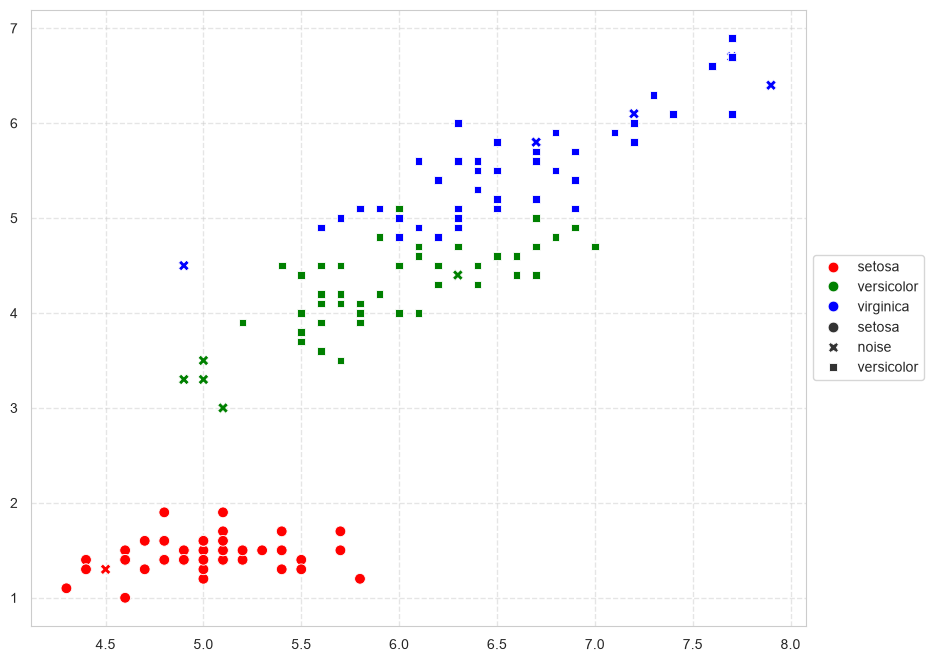

In [22]:
# Load Iris dataset
iris_obj = load_iris(as_frame=True)
df = iris_obj.frame.rename(columns={'target': 'species'})
df['species'] = df['species'].map(dict(enumerate(iris_obj.target_names)))
X = df.to_numpy()[:,0:4]
classes={-1: 'noise', 0 : 'setosa', 1 : 'versicolor', 2 : 'virginica', 3:'unknown'}

db = cl.DBSCAN(eps=0.55, metric='euclidean').fit(X)
db_labels = [classes[i] for i in db.labels_] 

plt.figure(figsize=(10, 8))
g = sns.scatterplot(x=X[:,0], y=X[:,2], hue=df['species'], s=60, style=db_labels,
                palette=sns.color_palette(['red', 'green', 'blue']))
g.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=1);

### Hierarchical Clustering & Dendrograms

+ Hierarchical clustering is an approach which does not require any parameters
+ Can be of two types: bottom-up or agglomerative as well as top-down or divisive
+ Here we consider the agglomerative variant, which is the most common type of hierarchical clustering
+ Dendrogram is built starting from the leaves and combining clusters up to the trunk

### Agglomerative Clustering & Linkage Criteria

**Algorithm**:

1. Start with each point in its own cluster
2. Identify the closest two clusters wrt. within-cluster variation measure and merge them 
3. Repeat until all points are in a single cluster

### Hierarchical Clustering: Case Study

- Suppose we have a generated data with three classes, shown in green, purple and orange
- How can we discover them from data?
<center>
    <img src="https://raw.githubusercontent.com/konstantin-schekotihin/dl_course/master/shared/images/hier_1.jpg" width="40%"/>
</center>
<p style="text-align:right">Copyright: ISLR</p>

### Hierarchical Clustering: Linkage Comparison

+ Complete dendrogram obtained using Euclidean distance and complete linkage, when the maximum distance is measured among all elements of a cluster 
+ Cuts at 9 and 5 allow to get the number of clusters

<center>
    <img src="https://raw.githubusercontent.com/konstantin-schekotihin/dl_course/master/shared/images/hier_2.jpg" width="60%"/>
</center>
<p style="text-align:right">Copyright: ISLR</p>

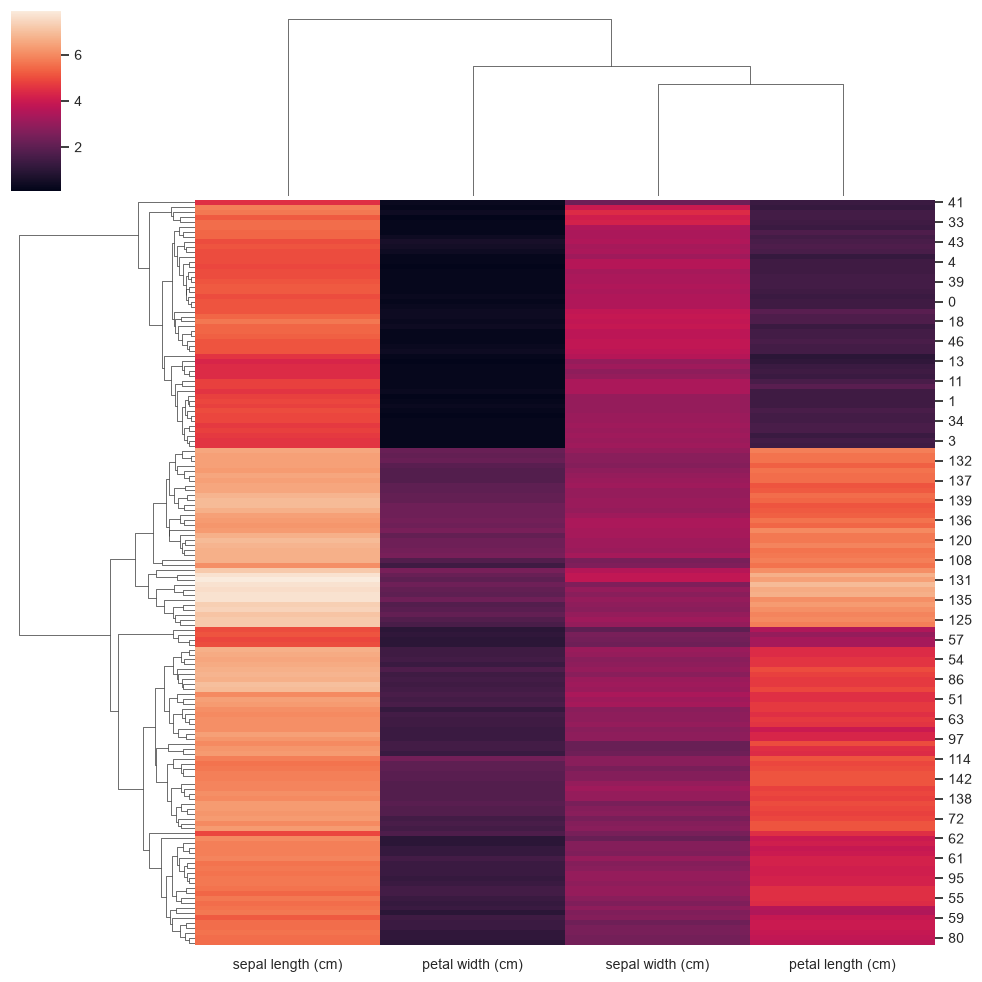

In [23]:
# Load Iris dataset
iris_obj = load_iris(as_frame=True)
df = iris_obj.frame.rename(columns={'target': 'species'})
df['species'] = df['species'].map(dict(enumerate(iris_obj.target_names)))
df.pop('species')
g = sns.clustermap(df)

## 4. Algorithm Selection Card: Unsupervised Learning (PCA & Clustering)

| Dimension | Assessment & Practical Guidance |
| :--- | :--- |
| **Best Suited For** | Exploratory data analysis, dimensionality reduction ($D \to 2$ or $3$ for visualization), latent feature extraction, and discovering natural groupings without ground-truth labels. |
| **Key Hyperparameters** | • **PCA**: Number of components $M$ or explained variance ratio threshold (e.g. $95\%$).<br>• **$K$-Means**: Number of clusters $K$ (tune via Elbow curve / Silhouette score); initialization (`k-means++`).<br>• **DBSCAN**: Neighborhood radius $\epsilon$ and minimum density samples `min_samples`.<br>• **Hierarchical**: Linkage criterion (`ward`, `complete`, `average`) and distance metric. |
| **Interpretability vs. Capacity** | **High Interpretability (Linear PCA / Centroids)**: Principal directions show exact feature loadings; cluster centroids summarize average cluster profiles. |
| **Critical Pitfalls** | • **Feature Scaling**: Standardization (`StandardScaler`) is mandatory for both PCA and distance-based clustering ($K$-Means, DBSCAN).<br>• **Cluster Assumptions**: $K$-Means assumes spherical, equally-sized clusters; use DBSCAN for arbitrary non-convex geometries or density variations.<br>• **Curse of Dimensionality**: Distance metrics lose contrast in high dimensions; run PCA before clustering when $D$ is large. |

> 💡 **Key Takeaway:** Unsupervised learning uncovers latent geometry and groupings without supervisor feedback. Always standardize features, validate cluster count $K$ across multiple diagnostics, and assess PCA explained variance before downstream modeling.